# Calibration of a SEIR–SEI Epidemic Model to Describe the Zika Virus Outbreak in Brazil

__Eber Dantas__, __Michel Tosin__ and __Americo Cunha Jr__, Universidade do Estado do Rio de Janeiro – UERJ, Nucleus of Modeling and Experimentation with Computers – NUMERICO, Rio de Janeiro, Brazil

Notebook: Claude (Anthropic) for P. Constantine, 2026

### Summary

Dantas, Tosin and Cunha Jr [[1]](#ref1) calibrate an eight-equation SEIR–SEI model of the 2016 Zika outbreak in Brazil (humans and *Aedes* mosquitoes) to the weekly counts of probable cases reported by the Brazilian Ministry of Health, and name an active-subspace study of the model as future work (p. 258). This notebook does that study: it varies the six transmission and progression rates and four initial conditions uniformly over the paper's calibration bounds and computes exact gradients of two quantities, the cumulative number of cases at the end of 2016 and the paper's least-squares misfit to the weekly data, from forward sensitivity equations. The logarithm of each quantity has a two-dimensional active subspace: the first direction is close to the gradient of the basic reproduction number, and the second is set by the initial proportion of infected mosquitoes.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs $\mathbf x\in[-1,1]^m$ with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T\rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If $\lambda_n \gg \lambda_{n+1}$, $f$ varies mostly along the first $n$ eigenvectors $\mathbf W_1$, and $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x)$; a plot of $f$ against the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ (a sufficient summary plot) shows this. We estimate $\mathbf C$ by Monte Carlo from gradient samples and bootstrap the eigenvalues and subspaces. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import active_subspaces as ac
import zika_model as zm

SEED = 2018                    # every rng= below
t_start = time.perf_counter()
labels = [r'$\alpha_h$', r'$\alpha_v$', r'$\gamma$', r'$\delta$', r'$\beta_h$', r'$\beta_v$',
          r'$E_{hi}$', r'$I_{hi}$', r'$E_{vi}$', r'$I_{vi}$']
names = list(zm.NAMES)
space = ac.Uniform(zm.LOWER, zm.UPPER, names=names)

### The model

Humans are susceptible, exposed, infectious or recovered ($S_h, E_h, I_h, R_h$, in people, $N_h = 206\times10^6$); mosquitoes are susceptible, exposed or infectious ($S_v, E_v, I_v$, proportions of a constant population $N_v = 1$). $C$ counts the humans who have become infectious. The paper's Eq. (1) is

$$
\begin{aligned}
\dot S_h &= -\beta_h S_h \frac{I_v}{N_v}, &
\dot S_v &= \delta N_v - \beta_v S_v \frac{I_h}{N_h} - \delta S_v,\\
\dot E_h &= \beta_h S_h \frac{I_v}{N_v} - \alpha_h E_h, &
\dot E_v &= \beta_v S_v \frac{I_h}{N_h} - (\alpha_v + \delta) E_v,\\
\dot I_h &= \alpha_h E_h - \gamma I_h, &
\dot I_v &= \alpha_v E_v - \delta I_v,\\
\dot R_h &= \gamma I_h, &
\dot C &= \alpha_h E_h .
\end{aligned}
$$

Time is in days. As in the paper (Sec. 3.1) and the authors' code, the run starts at $t_0 = 7$ (the end of epidemiological week, EW, 1 of 2016) with $C(7) = C_i = 8201$, and EW $w$ ends at $t = 7w$. The new cases in EW $w$ are $N_1 = C(7)$ and $N_w = C(7w) - C(7(w-1))$ (Eq. 3).

**Initial conditions.** The paper requires the compartments to add up, $S_{hi} = N_h - R_{hi} - E_{hi} - I_{hi}$ and $S_{vi} = 1 - E_{vi} - I_{vi}$, with $R_{hi} = 29{,}639$ held fixed. Its calibration varied $S_{hi}$ and $S_{vi}$ as separate unknowns, fitted the two sums as extra data points and corrected $S_{hi}$ and $S_{vi}$ afterwards (pp. 255–256). Here $S_{hi}$ and $S_{vi}$ are *derived* from the sums, so the study has $m = 10$ inputs, not 12. The paper's bound $S_{vi}\in[0.99, 0.999]$ is not used: its own nominal value (0.99956) and both calibrated values (1 and 0.999586) lie above 0.999.

**Ranges.** Rates: the lower and upper bounds of Tables 1–2. $E_{hi}, I_{hi}$: $[0, 10{,}000]$, Table 2 (the paper's preferred scenario). $E_{vi}, I_{vi}$: the paper's bounds are $[0, 1]$, which only state that they are proportions; we use $[0, 10^{-3}]$, which contains the nominal $2.2\times10^{-4}$ and the calibrated $4.14\times10^{-4}$, and is the size of change the paper calls already significant (pp. 255–256). This choice is ours (see `DATA.md`). The inputs are independent and uniform on the box.

**Quantities of interest.** (i) The cumulative number of cases at EW 52, $C_{52} = C(364)$ (people), the end point of the paper's Figs. 5a–6a. (ii) The misfit of Eq. (7), $J = \sum_{w=1}^{52}(y_w - N_w)^2$ (people²), with $y_w$ the weekly probable cases of 2016 (`data_cases.csv`). Both span several orders of magnitude over the box (an outbreak grows exponentially when the reproduction number exceeds one), so we analyze $\ln C_{52}$ and $\ln J$, whose gradients are $\nabla C_{52}/C_{52}$ and $\nabla J/J$.

**Solver and gradients.** `zika_model.py` scales the human compartments by $N_h$ and solves the seven states ($R_h$ follows from conservation) with their $7\times10$ forward sensitivities, using SciPy's `solve_ivp` (DOP853, rtol $10^{-11}$, atol $10^{-15}$). One solve with sensitivities takes about 0.04 s. The authors used MATLAB `ode45` (rtol $10^{-6}$); their code was read for its conventions only, not copied.

The inputs, from the code:

In [2]:
rows = ['| name | symbol | units | nominal | range (uniform) | source |', '|---|---|---|---|---|---|']
src = ['Tables 1–2'] * 6 + ['Table 2'] * 2 + ['chosen here'] * 2
for j, nm in enumerate(names):
    rows.append(f'| `{nm}` | {labels[j]} | {zm.UNITS[j]} | {zm.NOMINAL[j]:.4g} | '
                f'[{zm.LOWER[j]:.4g}, {zm.UPPER[j]:.4g}] | {src[j]} |')
display(Markdown('\n'.join(rows)))
print(f'held: N_h = {zm.N_H:.0f}, N_v = {zm.N_V:g}, R_hi = {zm.R_HI:.0f}, C_i = {zm.C_I:.0f}; '
      f'derived: S_hi = N_h - R_hi - E_hi - I_hi, S_vi = 1 - E_vi - I_vi')

| name | symbol | units | nominal | range (uniform) | source |
|---|---|---|---|---|---|
| `alpha_h` | $\alpha_h$ | 1/day | 0.1695 | [0.08333, 0.3333] | Tables 1–2 |
| `alpha_v` | $\alpha_v$ | 1/day | 0.1099 | [0.1, 0.2] | Tables 1–2 |
| `gamma` | $\gamma$ | 1/day | 0.1266 | [0.1136, 0.3333] | Tables 1–2 |
| `delta` | $\delta$ | 1/day | 0.09091 | [0.04762, 0.09091] | Tables 1–2 |
| `beta_h` | $\beta_h$ | 1/day | 0.0885 | [0.06135, 0.125] | Tables 1–2 |
| `beta_v` | $\beta_v$ | 1/day | 0.1163 | [0.08621, 0.1613] | Tables 1–2 |
| `E_hi` | $E_{hi}$ | people | 8201 | [0, 1e+04] | Table 2 |
| `I_hi` | $I_{hi}$ | people | 8201 | [0, 1e+04] | Table 2 |
| `E_vi` | $E_{vi}$ | - | 0.00022 | [0, 0.001] | chosen here |
| `I_vi` | $I_{vi}$ | - | 0.00022 | [0, 0.001] | chosen here |

held: N_h = 206000000, N_v = 1, R_hi = 29639, C_i = 8201; derived: S_hi = N_h - R_hi - E_hi - I_hi, S_vi = 1 - E_vi - I_vi


### The model against the paper

Before the parameter study, we run the model at the paper's nominal point and at its two calibrated points (Tables 1 and 2, with $S_{hi}$ derived as above) and compute the two numbers the paper quotes for each fit: the overshoot of $C_{52}$ over the data, and the difference between the model's and the data's peak weekly cases. The Table 1 point has $I_{hi} = 253{,}360$, outside this study's box; the Table 2 point is inside it.

In [3]:
y = zm.load_cases()                      # 52 weekly probable cases, 2016
pts = {'nominal (TRR input)': zm.NOMINAL,
       'Table 1 (TRR output)': np.r_[1/12, 1/10, 1/8.8, 1/16.86, 1/16.3, 1/11.6, 15089, 253360, 0, 0],
       'Table 2 (TRR output)': np.r_[1/12, 1/10, 1/3, 1/21, 1/10.40, 1/7.77, 6827, 10000, 4.14e-4, 0]}
Cw = {}
print(f'data: C_52 = {y.sum():.0f}, peak {y.max():.0f} cases in EW {y.argmax() + 1}')
for k, p in pts.items():
    Cw[k] = zm.trajectory(p)[:, 7]
    Nw = zm.new_cases(Cw[k])
    print(f'{k:22s} C_52 = {Cw[k][-1]:9.0f} ({100 * (Cw[k][-1] / y.sum() - 1):+6.2f} %), '
          f'peak {Nw.max():6.0f} in EW {Nw.argmax() + 1} ({100 * (Nw.max() / y.max() - 1):+6.2f} %), '
          f'J = {np.sum((y - Nw)**2):.3e}')

data: C_52 = 263099, peak 21280 cases in EW 7
nominal (TRR input)    C_52 =    165544 (-37.08 %), peak  21305 in EW 3 ( +0.12 %), J = 1.283e+09
Table 1 (TRR output)   C_52 =    280810 ( +6.73 %), peak  19745 in EW 6 ( -7.21 %), J = 1.345e+08
Table 2 (TRR output)   C_52 =    277855 ( +5.61 %), peak  19012 in EW 5 (-10.66 %), J = 2.521e+08


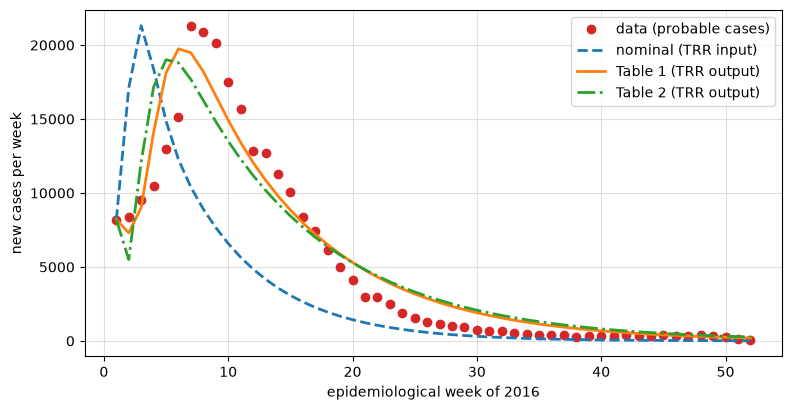

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(zm.WEEKS, y, 'o', color='tab:red', label='data (probable cases)')
for k, ls in zip(pts, ['--', '-', '-.']):
    ax.plot(zm.WEEKS, zm.new_cases(Cw[k]), ls, lw=2, label=k)
ax.set_xlabel('epidemiological week of 2016')
ax.set_ylabel('new cases per week')
ax.grid(True, alpha=.4)
ax.legend()
plt.close(fig)
fig

The calibrated points reproduce the paper's fits closely: the Table 1 fit overshoots the data's $C_{52}$ by 6.73 % (paper, p. 255: 6.00 %) and its peak weekly count is 7.21 % below the data's maximum and one week early (paper: 7.87 %, one week off); the Table 2 fit overshoots by 5.61 % (paper, p. 256: 5.74 %) and its peak is 10.66 % low and two weeks early (paper: 10.57 %, two weeks). The nominal parameters give an outbreak that peaks in EW 3 and reaches only 63 % of the data's total (37.08 % below); the paper also finds the nominal response not quantitatively realistic (Fig. 3, p. 253). The small differences are what one expects from the rounded parameter values printed in the tables (e.g. $1/16.86$, $1/10.40$) and from the paper's looser `ode45` tolerance. The data's total, 263,099 cases, is larger than the 215,319 probable cases the paper quotes from the Ministry's bulletin for the same period (p. 249); the weekly file is the one the authors fitted.

### Load the data

The 1000 samples, their two outputs and gradients were computed by `generate_data.py` (seed 2018, about 40 s). We check five rows against a fresh solve.

In [5]:
X = np.loadtxt('inputs.csv', delimiter=',')            # (M, 10) physical inputs
F = np.loadtxt('outputs.csv', delimiter=',')           # (M, 2): C_52 (people), J (people^2)
G = np.loadtxt('gradients.csv', delimiter=',')         # (M, 20): dC_52/dp, dJ/dp (physical)
C52, J = F[:, 0], F[:, 1]
dC52, dJ = G[:, :10], G[:, 10:]
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}')
chk = np.array([zm.qoi(x) for x in X[:5]])
print(f'max relative difference, fresh solve vs outputs.csv (rows 0-4): {np.max(np.abs(chk / F[:5] - 1)):.1e}')
print(f'C_52: {C52.min():.3g} to {C52.max():.3g} people (median {np.median(C52):.3g}); '
      f'J: {J.min():.3g} to {J.max():.3g} people^2')

inputs (1000, 10), outputs (1000, 2), gradients (1000, 20)


max relative difference, fresh solve vs outputs.csv (rows 0-4): 1.5e-12
C_52: 3.5e+04 to 1.54e+08 people (median 4.66e+05); J: 4.4e+08 to 7.09e+14 people^2


### Estimate the subspace

The gradients are exact (up to the solver tolerance), so we use the gradient estimator (`estimator="as"`): $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i\nabla f_i^T$ in normalized coordinates. We pass physical inputs and physical gradients of $\ln C_{52}$; v1 normalizes with the space. The bootstrap uses 500 replicates. The first eigenvector is oriented so that $\ln C_{52}$ increases along it, and the second so that its $I_{vi}$ component is positive.

In [6]:
lnC, g_lnC = np.log(C52), dC52 / C52[:, None]
sub = ac.active_subspace(space=space, X=X, grads=g_lnC, estimator='as', nboot=500, rng=SEED,
                         bootstrap_vectors=2, qoi='ln C52')
sub = ac.orient(sub, by='covariance', X=X, f=lnC, columns=1)
ref = sub.W.copy()
ref[:, 1] *= np.sign(ref[names.index('I_vi'), 1])
sub = ac.orient(sub, by='reference', reference=ref, columns=2)
lam = sub.eigenvalues
ks, crit, khat = ac.dimension_criterion(sub, rule='evg')
print('eigenvalues:', np.array2string(lam[:5], precision=3))
print(f'lambda_1/lambda_2 = {lam[0] / lam[1]:.2f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, '
      f'lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}; eigenvalue-gap rule picks n = {khat}')
print(f'(lambda_1 + lambda_2)/trace = {(lam[0] + lam[1]) / lam.sum():.3f}')

eigenvalues: [5.752 0.794 0.135 0.037 0.009]
lambda_1/lambda_2 = 7.25, lambda_2/lambda_3 = 5.90, lambda_3/lambda_4 = 3.69; eigenvalue-gap rule picks n = 1
(lambda_1 + lambda_2)/trace = 0.972


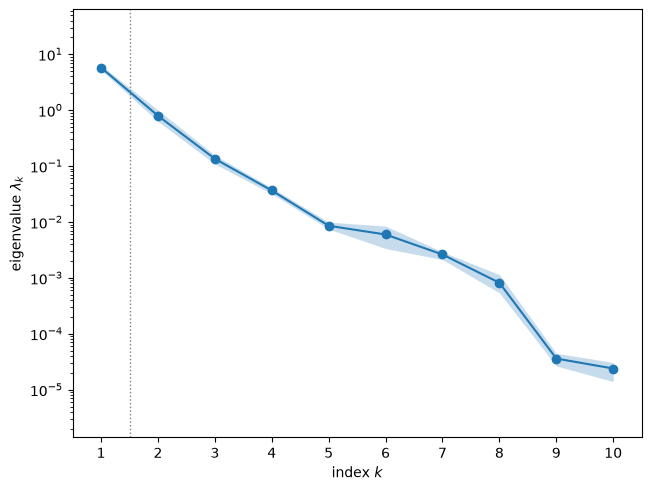

In [7]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
fig

The first two eigenvalues, 5.75 and 0.794, are separated from each other by a factor of 7.25 and from the third by a factor of 5.90; together they hold 97.2 % of the trace. The eigenvalue-gap rule picks $n = 1$, but the second gap is nearly as large as the first, so we keep both directions and use $n = 2$ below (the surrogate fits support this).

mean bootstrap subspace distance, k = 1..4: [0.024 0.045 0.036 0.043]


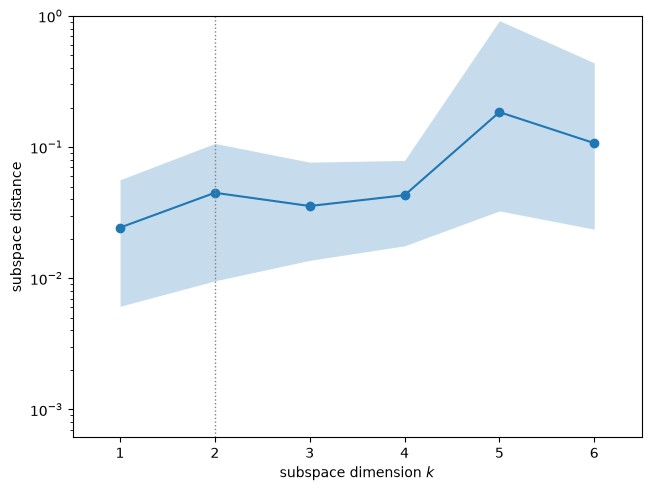

In [8]:
sub2 = ac.with_dimension(sub, 2)
dist = sub2.bootstrap_distances.mean(axis=0)
print('mean bootstrap subspace distance, k = 1..4:', np.array2string(dist[:4], precision=3))
fig, ax = ac.plotting.plot_subspace_errors(sub2, k_max=6)
fig

The mean bootstrap distance between the estimated and replicate subspaces is 0.024 for the one-dimensional subspace and 0.045 for the two-dimensional one (0.036 at $k = 3$), so the leading subspaces are well determined by the 1000 samples.

w1: alpha_h +0.02, alpha_v +0.11, gamma -0.62, delta -0.50, beta_h +0.41, beta_v +0.27, E_hi +0.01, I_hi +0.01, E_vi +0.19, I_vi +0.27
w2: alpha_h -0.03, alpha_v -0.01, gamma +0.41, delta +0.05, beta_h +0.01, beta_v -0.10, E_hi +0.03, I_hi +0.01, E_vi +0.50, I_vi +0.75


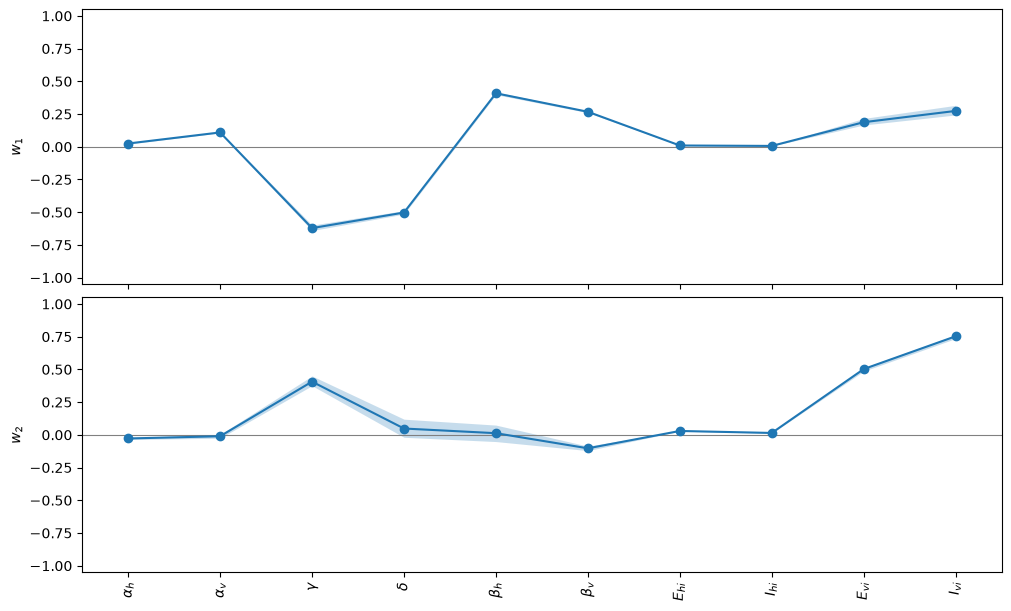

In [9]:
w1, w2 = sub2.W[:, 0], sub2.W[:, 1]
for k, w in enumerate([w1, w2]):
    print(f'w{k + 1}:', ', '.join(f'{nm} {w[j]:+.2f}' for j, nm in enumerate(names)))
fig, axes = ac.plotting.plot_eigenvectors(sub2, indices=[0, 1], labels=labels, interval='percentile',
                                          figsize=(10, 6))
fig

The first direction is dominated by the rates that set the reproduction number: the human recovery rate $\gamma$ (−0.62) and the mosquito death rate $\delta$ (−0.50) with negative weights, the transmission rates $\beta_h$ (+0.41) and $\beta_v$ (+0.27) with positive ones; $\ln C_{52}$ increases along $\mathbf w_1$, so a positive weight means that increasing the input enlarges the outbreak, and a shorter infectious period or mosquito lifespan shrinks it. The second direction is mostly the initial infected-mosquito proportions $I_{vi}$ (+0.75) and $E_{vi}$ (+0.50), with $\gamma$ (+0.41). The initial exposed and infectious humans, over $[0, 10{,}000]$, have weights of at most 0.03 in either vector: in this box, the mosquitoes infected at the start of 2016 drive the size of the outbreak, not the human cases.

The reproduction number of this model, from the next-generation matrix, satisfies $R_0^2 = \beta_h\beta_v\alpha_v/(\gamma\,\delta(\alpha_v+\delta))$ (the authors' code computes the same quantity). The cell below compares $\mathbf w_1$ with the average normalized gradient of $\ln R_0^2$.

In [10]:
def lnR0sq_grad(P):
    a_h, a_v, g, d, b_h, b_v = P[:, :6].T
    Gr = np.zeros_like(P)
    Gr[:, 1] = 1 / a_v - 1 / (a_v + d)
    Gr[:, 2] = -1 / g
    Gr[:, 3] = -1 / d - 1 / (a_v + d)
    Gr[:, 4], Gr[:, 5] = 1 / b_h, 1 / b_v
    return Gr * (zm.UPPER - zm.LOWER) / 2       # normalized coordinates

a = X[:, :6]
R0 = np.sqrt(a[:, 4] * a[:, 5] * a[:, 1] / (a[:, 2] * a[:, 3] * (a[:, 1] + a[:, 3])))
u = -lnR0sq_grad(X).mean(axis=0)
u /= np.linalg.norm(u)
print(f'|cos| between w1 and the mean normalized gradient of ln R0^2: {abs(u @ w1):.3f} '
      f'(angle {np.degrees(np.arccos(abs(u @ w1))):.0f} degrees)')
print(f'R0 over the samples: {R0.min():.2f} to {R0.max():.2f}; R0 > 1 for {np.mean(R0 > 1):.0%} of the samples')

|cos| between w1 and the mean normalized gradient of ln R0^2: 0.938 (angle 20 degrees)
R0 over the samples: 0.37 to 1.47; R0 > 1 for 8% of the samples


The first active direction is close to the average gradient of $\ln R_0^2$ ($|\cos| = 0.938$, an angle of 20°); the difference comes mostly from the initial mosquito infection, which enters $\mathbf w_1$ but not $R_0$. $R_0$ ranges from 0.37 to 1.47 over the box and exceeds one for 8 % of the samples; those samples make the large outbreaks, which is why $C_{52}$ itself spans more than three orders of magnitude.

### Sufficient summary plots

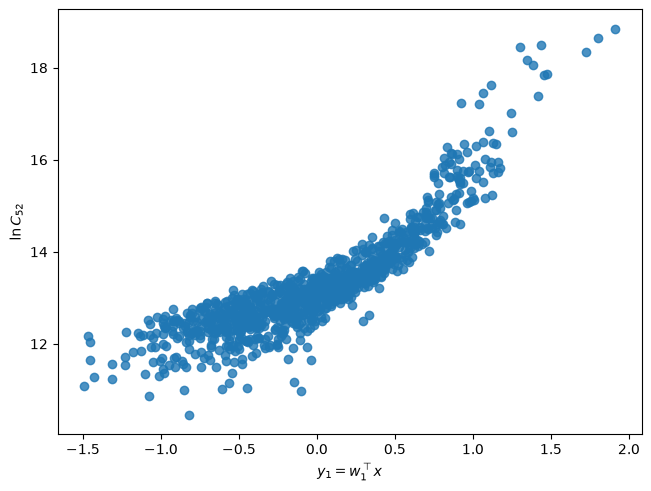

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(sub2, X=X, f=lnC, dims=1, qoi_label=r'$\ln C_{52}$')
fig

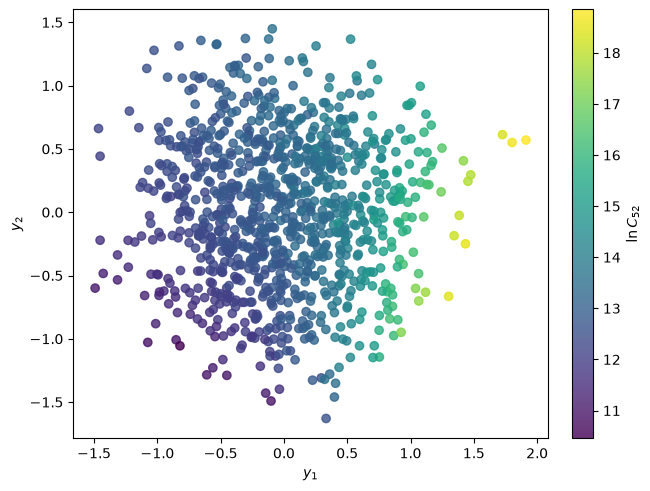

In [12]:
fig, ax = ac.plotting.plot_sufficient_summary(sub2, X=X, f=lnC, dims=2, qoi_label=r'$\ln C_{52}$')
fig

Against $y_1 = \mathbf w_1^T\mathbf x$ alone, $\ln C_{52}$ follows a clear increasing, upward-curving trend, with a vertical spread of about one unit of $\ln C_{52}$ (a factor of about three in cases) at fixed $y_1$. In the $(y_1, y_2)$ plane the color changes mostly with $y_1$ and also with $y_2$: at fixed $y_1$, larger initial mosquito infection (larger $y_2$) gives a larger outbreak. Polynomial fits on the active variables quantify this:

leave-one-out R^2 of polynomial surrogates for ln C52:
  n = 1, degree 2: 0.8753
  n = 1, degree 3: 0.8770
  n = 1, degree 4: 0.8834
  n = 2, degree 2: 0.9486
  n = 2, degree 3: 0.9722
  n = 2, degree 4: 0.9745


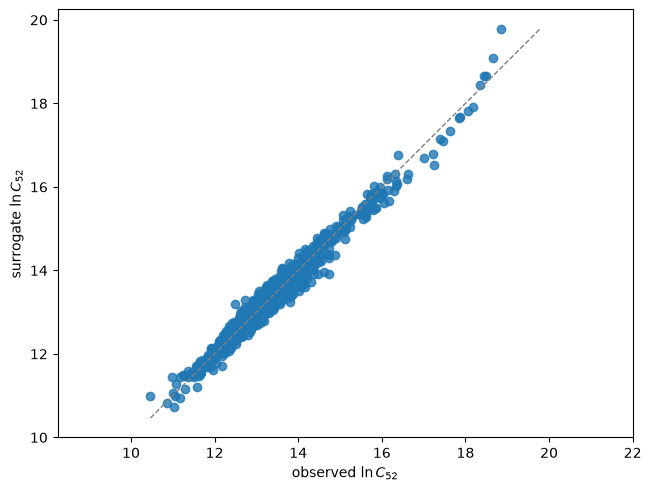

In [13]:
r2 = {}
for nn in (1, 2):
    for deg in (2, 3, 4):
        s = ac.fit_surrogate(X=X, f=lnC, subspace=ac.with_dimension(sub, nn), kind='poly', degree=deg)
        r2[nn, deg] = s.loo_r_squared
print('leave-one-out R^2 of polynomial surrogates for ln C52:')
for (nn, deg), v in r2.items():
    print(f'  n = {nn}, degree {deg}: {v:.4f}')
sur = ac.fit_surrogate(X=X, f=lnC, subspace=sub2, kind='poly', degree=3)
fig, ax = ac.plotting.plot_surrogate_fit(sur, X=X, f=lnC, qoi_label=r'$\ln C_{52}$')
fig

A cubic in one active variable reaches a leave-one-out $R^2$ of 0.877; a cubic in two reaches 0.972, and degree 4 adds little (0.975). Two active variables carry nearly all of the variation of $\ln C_{52}$ over the 10 inputs.

For comparison, the untransformed $C_{52}$ (cell below) has a much larger first gap, because its gradients are dominated by the few samples with large outbreaks, where $C_{52}$ grows exponentially along the $R_0$ direction; the summary plot is then a sharply curved one-dimensional trend that low-degree polynomials fit poorly (a cubic in $y_1$ has LOO $R^2$ = 0.710).

C52: lambda_1/lambda_2 = 262, lambda_2/lambda_3 = 1.55; |w1(C52) . w1(ln C52)| = 0.950
cubic in y1: LOO R^2 = 0.710


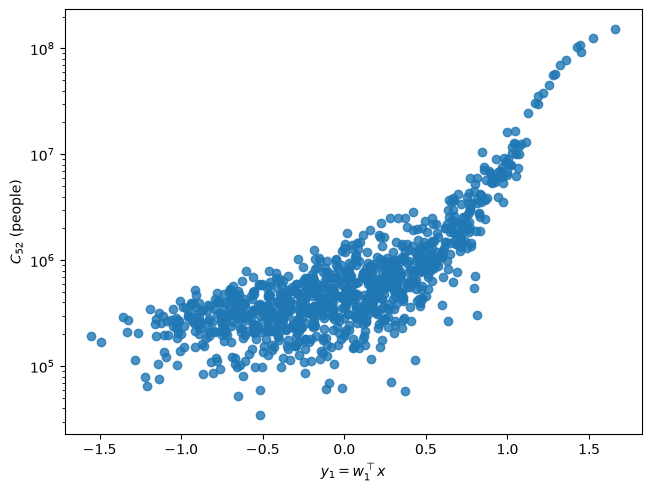

In [14]:
subC = ac.active_subspace(space=space, X=X, grads=dC52, nboot=200, rng=SEED, qoi='C52')
subC = ac.orient(subC, by='covariance', X=X, f=C52, columns=1)
lc = subC.eigenvalues
print(f'C52: lambda_1/lambda_2 = {lc[0] / lc[1]:.0f}, lambda_2/lambda_3 = {lc[1] / lc[2]:.2f}; '
      f'|w1(C52) . w1(ln C52)| = {abs(subC.W[:, 0] @ w1):.3f}')
print(f'cubic in y1: LOO R^2 = {ac.fit_surrogate(X=X, f=C52, subspace=ac.with_dimension(subC, 1), kind="poly", degree=3).loo_r_squared:.3f}')
fig, ax = ac.plotting.plot_sufficient_summary(ac.with_dimension(subC, 1), X=X, f=C52, dims=1,
                                              qoi_label=r'$C_{52}$ (people)')
ax.set_yscale('log')
fig

### The misfit $J$

The paper's calibration minimizes $J$ (Eq. 7). We repeat the analysis for $\ln J$ and mark the paper's Table 2 calibrated point on the summary plot; it lies in the box, on its boundary in $\gamma$, $\delta$ and $I_{vi}$.

In [15]:
lnJ, g_lnJ = np.log(J), dJ / J[:, None]
subJ = ac.active_subspace(space=space, X=X, grads=g_lnJ, nboot=500, rng=SEED, qoi='ln J')
subJ = ac.orient(subJ, by='reference', reference=sub2.W, columns=2)
subJ2 = ac.with_dimension(subJ, 2)
lj = subJ.eigenvalues
print(f'ln J: lambda_1/lambda_2 = {lj[0] / lj[1]:.2f}, lambda_2/lambda_3 = {lj[1] / lj[2]:.2f}, '
      f'rule picks n = {subJ.n}; mean bootstrap distance n = 1, 2: '
      f'{subJ.bootstrap_distances.mean(axis=0)[0]:.3f}, {subJ.bootstrap_distances.mean(axis=0)[1]:.3f}')
print(f'(lambda_1 + lambda_2)/trace = {(lj[0] + lj[1]) / lj.sum():.3f}')
print(f'|w1(ln J) . w1(ln C52)| = {abs(subJ.W[:, 0] @ w1):.3f}, '
      f'|w2(ln J) . w2(ln C52)| = {abs(subJ.W[:, 1] @ w2):.3f}')
print('w1(ln J):', ', '.join(f'{nm} {subJ.W[j, 0]:+.2f}' for j, nm in enumerate(names)))
print('w2(ln J):', ', '.join(f'{nm} {subJ.W[j, 1]:+.2f}' for j, nm in enumerate(names)))
for nn in (1, 2):
    s = ac.fit_surrogate(X=X, f=lnJ, subspace=ac.with_dimension(subJ, nn), kind='poly', degree=3)
    print(f'cubic surrogate for ln J, n = {nn}: LOO R^2 = {s.loo_r_squared:.4f}')
p2 = pts['Table 2 (TRR output)']
yT2 = space.to_normalized(p2[None, :]) @ subJ2.W[:, :2]
_, _, JT2, _ = zm.qoi_and_grad(p2)
print(f'Table 2 point: active variables ({yT2[0, 0]:+.2f}, {yT2[0, 1]:+.2f}), ln J = {np.log(JT2):.2f}; '
      f'smallest ln J among the samples: {lnJ.min():.2f}')
yJ = space.to_normalized(X) @ subJ2.W[:, :2]
low = np.argsort(lnJ)[:50]
print(f'the 50 samples with the smallest J: mean active variables ({yJ[low, 0].mean():+.2f}, {yJ[low, 1].mean():+.2f}), '
      f'all samples ({yJ[:, 0].mean():+.2f}, {yJ[:, 1].mean():+.2f})')

ln J: lambda_1/lambda_2 = 7.87, lambda_2/lambda_3 = 8.48, rule picks n = 1; mean bootstrap distance n = 1, 2: 0.018, 0.021
(lambda_1 + lambda_2)/trace = 0.975
|w1(ln J) . w1(ln C52)| = 0.996, |w2(ln J) . w2(ln C52)| = 0.972
w1(ln J): alpha_h +0.04, alpha_v +0.11, gamma -0.66, delta -0.49, beta_h +0.40, beta_v +0.27, E_hi +0.01, I_hi +0.01, E_vi +0.14, I_vi +0.21
w2(ln J): alpha_h +0.11, alpha_v +0.03, gamma +0.42, delta -0.01, beta_h +0.18, beta_v -0.11, E_hi +0.03, I_hi +0.01, E_vi +0.46, I_vi +0.74
cubic surrogate for ln J, n = 1: LOO R^2 = 0.7745
cubic surrogate for ln J, n = 2: LOO R^2 = 0.9552
Table 2 point: active variables (-0.48, -0.51), ln J = 19.35; smallest ln J among the samples: 19.90
the 50 samples with the smallest J: mean active variables (-0.08, -0.84), all samples (-0.02, -0.00)


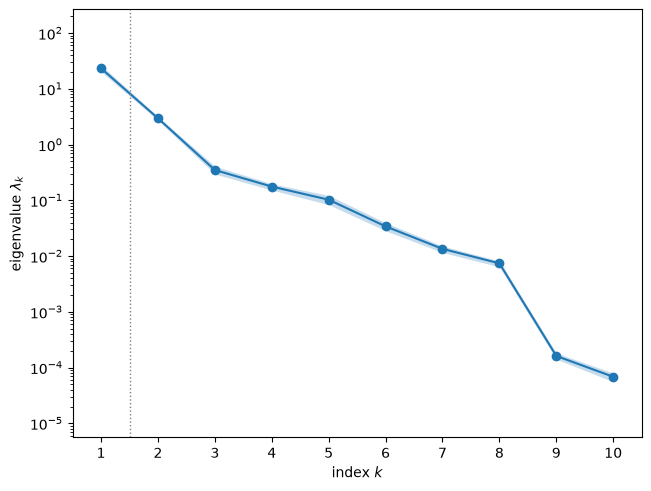

In [16]:
fig, ax = ac.plotting.plot_eigenvalues(subJ)
fig

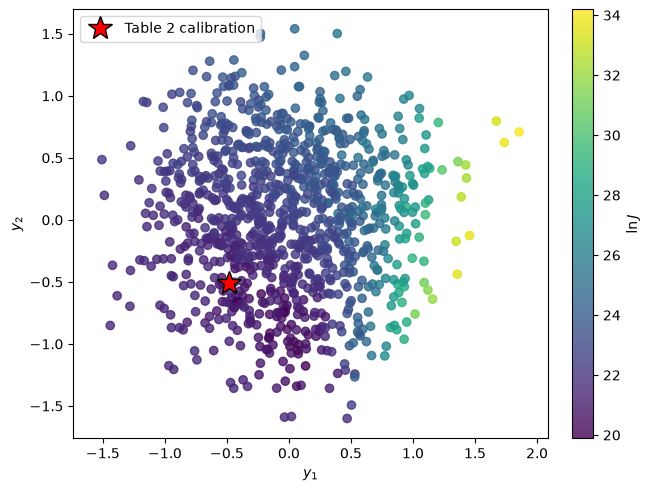

In [17]:
fig, ax = ac.plotting.plot_sufficient_summary(subJ2, X=X, f=lnJ, dims=2, qoi_label=r'$\ln J$')
ax.plot(yT2[0, 0], yT2[0, 1], 'r*', ms=18, mec='k', label='Table 2 calibration')
ax.legend(loc='upper left')
fig

$\ln J$ has the same structure: gaps of 7.87 and 8.48, and first and second eigenvectors that agree with those of $\ln C_{52}$ to 0.996 and 0.972 in absolute inner product. The first two eigenvalues hold 97.5 % of the trace, and a cubic in two active variables has LOO $R^2 = 0.955$ (one variable: 0.775). The misfit is smallest in the lower part of the $(y_1, y_2)$ plane (small $y_2$): the 50 samples with the smallest $J$ have mean active variables (−0.08, −0.84), against (−0.02, 0.00) for all samples. The paper's Table 2 calibration is also in the lower half, at (−0.48, −0.51), with $\ln J = 19.35$, below the smallest of the 1000 samples (19.90). So the fit to the weekly data depends, to a good approximation, on two linear combinations of the 10 inputs, and the other eight directions change it little. Parameter sets with nearly the same two active variables fit nearly equally well, consistent with the paper's finding of two quite different calibrations (Tables 1 and 2) that both describe the data reasonably.

### Comparison with the paper

The paper reports no active-subspace results (it names the analysis as future work, p. 258). The quantities it does report are compared below.

| quantity | paper value | notebook value |
|---|---|---|
| Table 1 fit: overshoot of $C_{52}$ over the data | 6.00 % (p. 255) | +6.73 % |
| Table 1 fit: peak $N_w$ vs. data maximum | 7.87 %, one week off (p. 255) | −7.21 %, EW 6 vs. EW 7 |
| Table 2 fit: overshoot of $C_{52}$ | 5.74 % (p. 256) | +5.61 % |
| Table 2 fit: peak $N_w$ vs. data maximum | 10.57 %, two weeks off (p. 256) | −10.66 %, EW 5 vs. EW 7 |
| Misfit $J$ at the Table 1 / Table 2 fits | not reported | 1.345e8 / 2.521e8 people² |
| Response to the initial infectious vectors $I_{vi}$ | "very sensible" (p. 253) | largest weight of $\mathbf w_2$ for $\ln C_{52}$ (+0.75) |
| Response to $I_{hi}$ ($= E_{hi}$, 1,000 to 60,000; Fig. 8) | $C$ and $N_w$ rise with $I_{hi}$ | weights of $E_{hi}$, $I_{hi}$ at most 0.03 over $[0, 10{,}000]$ |
| Active-subspace eigenvalues, eigenvectors | not reported (future work, p. 258) | $\ln C_{52}$: $\lambda_1/\lambda_2 = 7.25$, $\lambda_2/\lambda_3 = 5.90$; $\ln J$: 7.87, 8.48 |
| Surrogate on the active variables | not reported | cubic, $n = 2$: LOO $R^2$ = 0.972 ($\ln C_{52}$), 0.955 ($\ln J$) |
| Total probable cases, EW 1–52 of 2016 | 215,319 (bulletin, p. 249) | 263,099 (sum of the weekly file the authors fitted) |

In [18]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 3 s


### References

<a id="ref1"></a>[1] E. Dantas, M. Tosin and A. Cunha Jr, Calibration of a SEIR–SEI epidemic model to describe the Zika virus outbreak in Brazil, *Applied Mathematics and Computation* 338:249–259, 2018. [doi:10.1016/j.amc.2018.06.024](https://doi.org/10.1016/j.amc.2018.06.024). Preprint: arXiv:2105.06036. Code and data: [github.com/americocunhajr/ARBO](https://github.com/americocunhajr/ARBO) (MIT licence).

[2] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

[3] T. F. Coleman and Y. Li, An interior, trust region approach for nonlinear minimization subject to bounds, *SIAM J. Optim.* 6(2):418–445, 1996. [doi:10.1137/0806023](https://doi.org/10.1137/0806023) (the paper's calibration method).

### Acknowledgments

The paper's authors acknowledge financial support from the Brazilian agencies CNPq, CAPES and FAPERJ. The weekly case data are from the Brazilian Ministry of Health (SINAN), as distributed with the authors' ARBO code.